In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import time

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("libraries imported successfully!")

libraries imported successfully!


In [8]:
!pip install -U importlib_resources tensorflow-datasets

In [9]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    'cats_vs_dogs',
    split='train',
    with_info=True,
    as_supervised=True
)

print("Dataset loaded successfully!")
print("Total Images:", info.splits['train'].num_examples)

Dataset loaded successfully!
Total Images: 23262


In [10]:
# resize images to 224 × 224 because ResNet50 expects this input size.

IMG_SIZE=224
BATCH_SIZE=32

def preprocess_image(image, label):
  image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
  image = tf.cast(image, tf.float32)
  image = preprocess_input(image)
  return image, label

dataset = dataset.filter(
    lambda image, label: tf.reduce_all(tf.shape(image) > 0)
)

dataset = dataset.shuffle(1000, seed=42)

total = info.splits['train'].num_examples
train_size = int(total * 0.8)
val_size = int(total * 0.1)

train_ds = dataset.take(train_size)
remaining_ds = dataset.skip(train_size)
val_ds = remaining_ds.take(val_size)
test_ds = remaining_ds.skip(val_size)

train_ds = train_ds.map(
    preprocess_image, num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_image, num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_image, num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Dataset preprocessed successfully!")

Dataset preprocessed successfully!


In [11]:
print("Training samples:", train_size)
print("Validation samples:", val_size)
print("Testing samples:", total - train_size - val_size)

Training samples: 18609
Validation samples: 2326
Testing samples: 2327


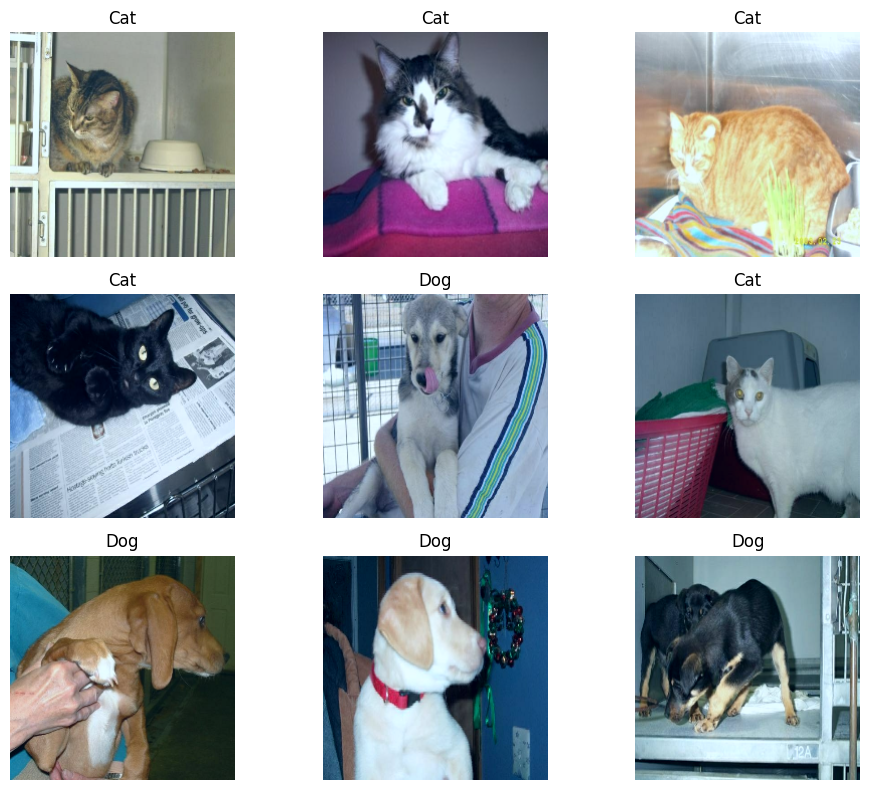

In [13]:
# Display sample images

plt.figure(figsize=(10,8))

for image, labels in train_ds.take(1):

  for i in range(9):
    plt.subplot(3, 3, i+1)
    img = image[i].numpy()
    img = img[:, :, ::-1]
    img += [103, 116, 123]
    img = np.clip(img / 255.0, 0, 1)

    plt.imshow(img)
    plt.title("Dog" if labels[i].numpy() == 1 else "Cat")
    plt.axis("off")

plt.grid(False)
plt.tight_layout()
plt.show()

In [14]:
from tensorflow.python.util.traceback_utils import include_frame
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

print("ResNet50 loaded successfully!")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
ResNet50 loaded successfully!


In [15]:
# Freeze pretrained layers
base_model.trainable = False
print("Total layers: ", len(base_model.layers))

Total layers:  175


In [16]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [17]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [19]:
start_time = time.time()

hist_fr = model.fit(
    train_ds, validation_data=val_ds,
    epochs=5
)

end_time = time.time()

total_time = end_time - start_time
print("Total time taken: ", total_time)

Epoch 1/5
    582/Unknown 104s 140ms/step - accuracy: 0.9678 - loss: 0.0929

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


582/582 ━━━━━━━━━━━━━━━━━━━━ 136s 195ms/step - accuracy: 0.9805 - loss: 0.0609 - val_accuracy: 0.9875 - val_loss: 0.0309
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 110s 163ms/step - accuracy: 0.9874 - loss: 0.0378 - val_accuracy: 0.9897 - val_loss: 0.0259
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 97s 162ms/step - accuracy: 0.9897 - loss: 0.0301 - val_accuracy: 0.9841 - val_loss: 0.0402
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 135s 230ms/step - accuracy: 0.9922 - loss: 0.0236 - val_accuracy: 0.9897 - val_loss: 0.0237
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 78s 133ms/step - accuracy: 0.9927 - loss: 0.0206 - val_accuracy: 0.9893 - val_loss: 0.0322
Total time taken:  556.0756530761719


In [20]:
frozen_loss, frozen_acc = model.evaluate(test_ds)
print("Test Accuracy:", frozen_acc)
print("Test Loss:", frozen_loss)

73/73 ━━━━━━━━━━━━━━━━━━━━ 27s 139ms/step - accuracy: 0.9893 - loss: 0.0300
Test Accuracy: 0.9892565608024597
Test Loss: 0.030003156512975693


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [21]:
# Unfreeze selected layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
  if isinstance(layer, layers.BatchNormalization):
    layer.trainable = False

In [22]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.00001),
    metrics=["accuracy"],
    loss="binary_crossentropy"
)

In [23]:
start_time = time.time()

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

finetune_time = time.time() - start_time

print("Fine-tuning Time:", finetune_time, "seconds")

Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 272s 364ms/step - accuracy: 0.9855 - loss: 0.0375 - val_accuracy: 0.9936 - val_loss: 0.0181
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 205s 315ms/step - accuracy: 0.9956 - loss: 0.0141 - val_accuracy: 0.9910 - val_loss: 0.0252
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 185s 315ms/step - accuracy: 0.9978 - loss: 0.0073 - val_accuracy: 0.9927 - val_loss: 0.0242
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 202s 316ms/step - accuracy: 0.9986 - loss: 0.0045 - val_accuracy: 0.9940 - val_loss: 0.0161
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 185s 315ms/step - accuracy: 0.9983 - loss: 0.0050 - val_accuracy: 0.9893 - val_loss: 0.0296
Fine-tuning Time: 1048.7101719379425 seconds


In [24]:
finetune_loss, finetune_accuracy = model.evaluate(test_ds)

print("Fine-Tuning Results")
print("Test Loss:", finetune_loss)
print("Test Accuracy:", finetune_accuracy * 100, "%")

73/73 ━━━━━━━━━━━━━━━━━━━━ 26s 122ms/step - accuracy: 0.9897 - loss: 0.0306
Fine-Tuning Results
Test Loss: 0.03063715063035488
Test Accuracy: 98.96863102912903 %


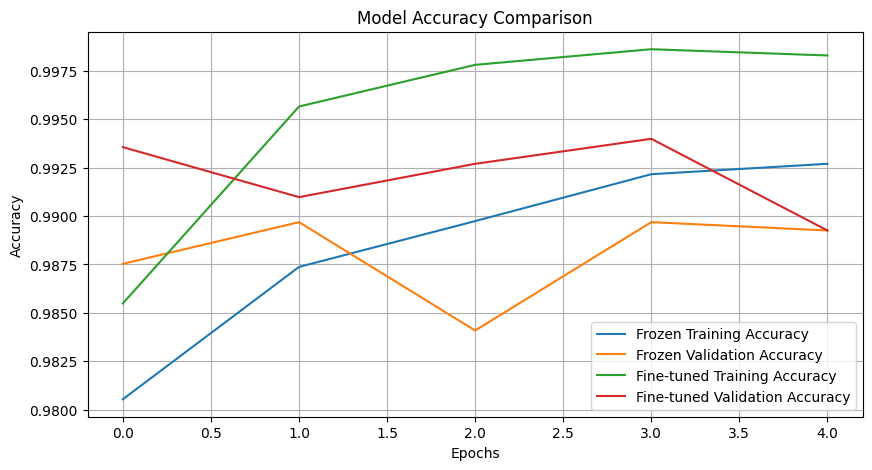

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    hist_fr.history['accuracy'],
    label='Frozen Training Accuracy'
)

plt.plot(
    hist_fr.history['val_accuracy'],
    label='Frozen Validation Accuracy'
)

plt.plot(
    np.array(history_finetune.history['accuracy']),
    label='Fine-tuned Training Accuracy'
)

plt.plot(
    np.array(history_finetune.history['val_accuracy']),
    label='Fine-tuned Validation Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

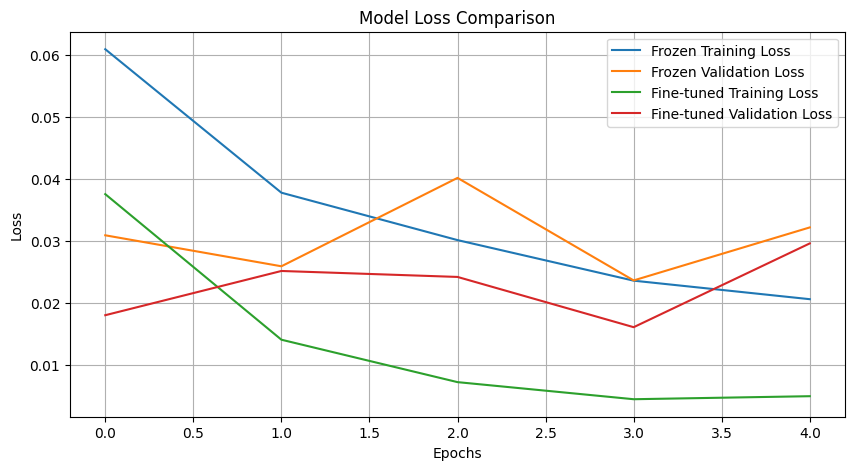

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    hist_fr.history['loss'],
    label='Frozen Training Loss'
)

plt.plot(
    hist_fr.history['val_loss'],
    label='Frozen Validation Loss'
)

plt.plot(
    history_finetune.history['loss'],
    label='Fine-tuned Training Loss'
)

plt.plot(
    history_finetune.history['val_loss'],
    label='Fine-tuned Validation Loss'
)

plt.title('Model Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()